In [2]:
'''
Temp visualisation, SWI, 

By Anita T

October 13 2023
'''

'\nTemp visualisation, SWI, \n\nBy Anita T\n\nOctober 13 2023\n'

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0)
import seaborn as sns
from scipy import stats
from scipy.stats import norm

In [2]:
Datat = pd.read_csv('finalformofData.csv')
Datat.columns = Datat.columns.str.strip()

DropDF1 = ['', 'Unnamed: 0.1', 'Unnamed: 0', 'LOCATION', 'History ID','Closest Longitude', 'Closest Latitude', 'Station ID', 'DATE_merged', 'Native ID', 'month', 'Station Name', 'EMS ID', 'Aquifer ID Number','Well Tag Number','LONGITUDE','LATITUTE']
Datat = Datat.drop(DropDF1, axis=1, errors='ignore')

Datat['FD'] = Datat['PRECIPITATION']-Datat['Precip_Climatology']
Datat['HW'] = Datat['MAX_TEMP']-Datat['Tx_Climatology']
Datat['MT'] = Datat['MIN_TEMP']-Datat['Tn_Climatology']

def assign_group(aquifer_type):
    if aquifer_type in ['1a', '1b', '1c', '2', '3', '4a']:
        return '1'
    elif aquifer_type in ['4b', '4c']:
        return '2'
    elif aquifer_type in ['5a', '6a', '6b']:
        return '3'
    elif aquifer_type == '5b':
        return '4'
    else:
        return '5'
    
Datat['Aquifer Group'] = Datat['Aquifer Subtype'].apply(assign_group)
#one_hot_df = pd.get_dummies(Datat['Aquifer Group'], prefix='Aquifer') #Uncomment both for regression, etc
#Datat = pd.concat([Datat, one_hot_df], axis=1)
Datat = Datat.dropna()
Datawithtime = Datat.copy()
DropDF2 = ['Aquifer Subtype', 'DATE', 'OBSWELL', 'year_month', 'Precip_Climatology',
       'Tn_Climatology', 'Tx_Climatology',]
Datat = Datat.drop(DropDF2, axis=1, errors='ignore')

In [3]:
'''
pH_values = Datat['pH'].values
median_pH = np.median(pH_values)
mad_pH = np.median(np.abs(pH_values - median_pH))

print("Unique pH values:", np.unique(pH_values))
print("Median Absolute Deviation of pH:", mad_pH)

'''

'\npH_values = Datat[\'pH\'].values\nmedian_pH = np.median(pH_values)\nmad_pH = np.median(np.abs(pH_values - median_pH))\n\nprint("Unique pH values:", np.unique(pH_values))\nprint("Median Absolute Deviation of pH:", mad_pH)\n\n'

In [4]:
'''
Heatw Analysis 
'''
df_Heatw = Datat[Datat['HW'] > 0]
df_Heatw.shape

(611, 24)

In [5]:
filtered_dfAs = df_Heatw [(df_Heatw ['As-T'] >= 0.01)]
filtered_dfAs.shape

(38, 24)

In [8]:
filtered_dfMn = df_Heatw [(df_Heatw ['Mn-T'] >= 0.12)]
filtered_dfMn.shape

(190, 24)

In [9]:
filtered_dfPb = df_Heatw [(df_Heatw ['Pb-T'] >= 0.005)]
filtered_dfPb.shape

(151, 24)

In [10]:
filtered_dfU = df_Heatw [(df_Heatw ['U--T'] >= 0.02)]
filtered_dfU.shape

(4, 24)

In [11]:
filtered_dSC = df_Heatw [(df_Heatw ['Specific Conductance'] >= 1000)]
filtered_dSC.shape

(66, 24)

In [12]:
filtered_dTDS = df_Heatw [(df_Heatw ['Residue Filterable 1.0u'] >= 750)]
filtered_dTDS.shape

(44, 24)

In [13]:
filtered_dC = df_Heatw [(df_Heatw ['Chlrid:D'] >= 150)]
filtered_dC.shape

(31, 24)

Datat.columns


#You can adjust the `k` parameter to control how aggressive the outlier detection is. The default value of 1.5 corresponds to approximately ±2.7σ or 99.3% coverage if the data is normally distributed.

numeric_cols = ['pH']
cleaned_dataset_array = replace_outliers_with_iqr(Datat[numeric_cols], 1.5)


In [5]:
'''
Handling Outliers

Notes:  
To prevent more outlier removal, use MAD score.  ID datat style.  Will not to Mahalanobis method due to complexity

Decided to use threshold score instead.  MAD scores takes away from metals being past the drinking water standard and SWI values

Source:
https://stats.stackexchange.com/questions/591853/interquartile-range-finding-more-than-10-times-outliers-than-zscore#:~:text=Yes%20%2D%20using%20the%20IQR%20method,will%20find%20lots%20of%20outliers.
https://saturncloud.io/blog/how-to-detect-and-exclude-outliers-in-a-pandas-dataframe/#:~:text=The%20IQR%20can%20be%20calculated,can%20be%20considered%20an%20outlier.
https://www.analyticsvidhya.com/blog/2021/05/detecting-and-treating-outliers-treating-the-odd-one-out/
'''

def replace_outliers_with_iqr(dataset, k=1.5):
    cleaned_dataset = dataset.copy()
    for col in cleaned_dataset.columns:
        Q1 = cleaned_dataset[col].quantile(0.25)
        Q3 = cleaned_dataset[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_threshold = Q1 - k * IQR
        upper_threshold = Q3 + k * IQR
        cleaned_dataset.loc[cleaned_dataset[col] < lower_threshold, col] = lower_threshold
        cleaned_dataset.loc[cleaned_dataset[col] > upper_threshold, col] = upper_threshold
    return cleaned_dataset

#You can adjust the `k` parameter to control how aggressive the outlier detection is. The default value of 1.5 corresponds to approximately ±2.7σ or 99.3% coverage if the data is normally distributed.

numeric_cols1 = ['pH', 'Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T', 'Chlrid:D', 'Fe-T',
       'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'Hardness Total (T)', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP']
cleaned_dataset_array1 = replace_outliers_with_iqr(df_Heatw[numeric_cols1], 1.5)
Datat[numeric_cols1] = cleaned_dataset_array1


def replace_outliers_with_threshold(dataset, threshold_multiplier=3):
    """
    Replace outliers in a dataset with the threshold value based on the Median Absolute Deviation (MAD).

    Parameters:
    - dataset: DataFrame containing the dataset.
    - threshold_multiplier: Multiple of the MAD to be used as the threshold (default: 3).

    Returns:
    - cleaned_dataset: DataFrame with outliers replaced by the threshold.
    """
    cleaned_dataset = dataset.copy()
    for col in cleaned_dataset.columns:
        col_values = cleaned_dataset[col].values
        median = np.median(col_values)
        mad = np.median(np.abs(col_values - median))
        lower_threshold = median - threshold_multiplier * mad
        upper_threshold = median + threshold_multiplier * mad
        high_outliers = (col_values - median) > upper_threshold
        cleaned_dataset.loc[high_outliers, col] = upper_threshold
        # Update col_values after replacing high outliers
        col_values = cleaned_dataset[col].values
        low_outliers = (col_values - median) < lower_threshold
        cleaned_dataset.loc[low_outliers, col] = lower_threshold
    return cleaned_dataset
'''
# Assume Datat is your DataFrame
numeric_cols = [ 'FD', 'HW', 'MT']

# Call your function on just the numeric columns
cleaned_dataset_array = replace_outliers_with_threshold(Datat[numeric_cols], threshold_multiplier=3)

# Convert the numpy array back to a DataFrame
cleaned_dataset = pd.DataFrame(cleaned_dataset_array, columns=numeric_cols, index=Datat.index)

Datat[numeric_cols] = cleaned_dataset
'''
Datatpastremoval1 = df_Heatw.copy() #This is incase I screw up. Can be commented out.

#cleaned_dataset.to_csv('cleaned_dataset.csv')

In [6]:
Datat.head()

,Alkalinity Total 4.5,As-T,Ca-T,Cd-T,Chlrid:D,Fe-T,Mn-T,N.Kjel:T,P--T,Pb-T,...,Hardness Total (T),K--T,U--T,PRECIPITATION,MIN_TEMP,MAX_TEMP,FD,HW,MT,Aquifer Group
0,272.0,0.00210,70.0,0.000045,28.8,1.7043,0.0970,0.240,0.092,0.000345,...,250.37666,-0.52,0.000001,60.4,8.693548,22.290323,22.5657,-2.590000,-0.965552,1
1,228.0,0.00210,70.0,0.000045,28.8,1.7043,0.1090,0.005,0.106,0.000345,...,250.37666,3.56,0.000001,44.6,10.596774,26.032258,-4.9586,-0.458242,0.469774,1
2,228.0,0.00210,70.0,0.000010,28.8,1.7043,0.1100,0.200,0.100,0.000290,...,250.37666,3.56,0.000053,53.7,6.096774,21.709677,8.5384,2.203777,1.175854,1
3,228.0,0.00210,70.0,0.000010,28.8,1.7043,0.0969,0.160,0.099,0.000030,...,250.37666,3.56,0.000053,109.0,3.161290,-2.624694,60.3676,0.253052,2.162414,1
4,228.0,0.00249,70.0,0.000005,28.8,1.7800,0.0955,0.140,0.064,0.000020,...,250.37666,3.56,0.000053,44.5,10.693548,27.903226,6.6657,1.550026,1.034448,1


In [7]:
from sklearn.preprocessing import PowerTransformer

# Create a PowerTransformer object
pt = PowerTransformer(method='yeo-johnson')

# Define the column names you want to transform
cols_to_transform = ['Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T', 'Chlrid:D', 'Fe-T',
       'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'Hardness Total (T)', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP']
# Apply the transformation to the specified columns
df_Heatw[cols_to_transform] = pt.fit_transform(df_Heatw[cols_to_transform])

In [9]:
df_Heatw.shape

(611, 24)

In [10]:
df_Heatw.to_csv('df_Heatw.csv')

In [11]:
df_Heatw.shape

(611, 24)

In [12]:
df_Heatw.columns

Index(['Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T', 'Chlrid:D', 'Fe-T',
       'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'pH', 'Hardness Total (T)', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT',
       'Aquifer Group'],
      dtype='object')

In [13]:
# import pandas and numpy if they're not already imported
import pandas as pd
import numpy as np

# assuming `df` is your DataFrame
selected_columns = df_Heatw.iloc[:, :23]  # select the first 26 columns
group_column = df_Heatw.iloc[:, 23]  # select the 27th column

# group the selected columns by the values in the group column
grouped = selected_columns.groupby(group_column)

# get the unique group names
groups = df_Heatw.iloc[:, 23].unique()

# calculate summary statistics and percentiles for each group
all_summaries3 = []  # list to hold summary dataframes for each group
for group in groups:
    # select data for this group
    this_group = grouped.get_group(group)

    # calculate summary statistics
    summary = this_group.agg(['mean', 'var', 'std', 'min', 'max', 'skew', 'median', pd.DataFrame.kurt])

    # calculate percentiles and add them to the summary
    for q in [0.1, 0.5, 0.9]:
        summary.loc[f'{q*100}% percentile'] = this_group.quantile(q)

    # calculate coefficient of variation and add it to the summary
    summary.loc['cv'] = this_group.std() / this_group.mean()

    # add the group name as the top level of the index
    summary.index = pd.MultiIndex.from_product([[group], summary.index])

    # add this group's summary to the list
    all_summaries3.append(summary)

# concatenate all the group summaries into one DataFrame
summary_df3 = pd.concat(all_summaries3)

# save to CSVWhich is the best given datasets have range between 0.000001-0.027475 in one column and 3580.000000-0.025000 in another?


summary_df3.to_csv('Stats/statssummaryHeatw.csv')

# check the DataFrame
print(summary_df3)

                    Alkalinity Total 4.5      As-T        Ca-T       Cd-T  \
1 mean                         -0.372846 -0.173767   -0.007237  -0.082165   
  var                           0.712412  1.081807    0.596297   0.870390   
  std                           0.844045  1.040099    0.772202   0.932947   
  min                          -2.380736 -1.240027   -2.182770  -1.123380   
  max                           2.337000  1.663737    2.327947   1.585117   
  skew                          0.927713  0.551385    0.907756   0.350834   
  median                       -0.614538 -0.832133   -0.199417  -0.323970   
  kurt                          1.038456 -1.432156    0.383498  -1.472311   
  10.0% percentile             -1.038684 -1.137173   -0.831133  -1.123380   
  50.0% percentile             -0.614538 -0.832133   -0.199417  -0.323970   
  90.0% percentile              1.271225  1.334386    1.391980   1.251046   
  cv                           -2.263790 -5.985597 -106.696078 -11.354536   

In [14]:
correlation_matHeatw = df_Heatw.corr()
correlation_matHeatw.to_csv('Stats/correlation_matafterHeatw.csv')
print(correlation_matHeatw)


                         Alkalinity Total 4.5      As-T      Ca-T      Cd-T  \
Alkalinity Total 4.5                 1.000000  0.351791  0.493878 -0.146364   
As-T                                 0.351791  1.000000  0.255417  0.037411   
Ca-T                                 0.493878  0.255417  1.000000 -0.089032   
Cd-T                                -0.146364  0.037411 -0.089032  1.000000   
Chlrid:D                             0.325195 -0.000567  0.211521  0.114080   
Fe-T                                -0.009209  0.198691 -0.047082  0.437281   
Mn-T                                 0.175392  0.364337  0.182322  0.174631   
N.Kjel:T                             0.187727  0.085517  0.135697  0.062148   
P--T                                 0.105059  0.249214  0.020971  0.097782   
Pb-T                                -0.036682  0.165333 -0.088594  0.656597   
Residue Filterable 1.0u              0.733614  0.271252  0.581101 -0.039310   
Specific Conductance                 0.769486  0.259

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_84644\1996390039.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_matHeatw = df_Heatw.corr()


In [15]:
correlation_tauHeatw = df_Heatw.corr(method='kendall')
print(correlation_tauHeatw)
correlation_tauHeatw.to_csv('Stats/correlation_tauHeatw.csv')

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_84644\2588988533.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_tauHeatw = df_Heatw.corr(method='kendall')


                         Alkalinity Total 4.5      As-T      Ca-T      Cd-T  \
Alkalinity Total 4.5                 1.000000  0.304549  0.410083 -0.138227   
As-T                                 0.304549  1.000000  0.209383  0.015041   
Ca-T                                 0.410083  0.209383  1.000000 -0.090107   
Cd-T                                -0.138227  0.015041 -0.090107  1.000000   
Chlrid:D                             0.228012  0.007727  0.163308  0.082504   
Fe-T                                -0.030235  0.118009 -0.063167  0.346399   
Mn-T                                 0.100126  0.234048  0.088745  0.150430   
N.Kjel:T                             0.118216  0.030842  0.094431 -0.017617   
P--T                                 0.088923  0.198712  0.019004  0.113936   
Pb-T                                 0.002266  0.132370 -0.051116  0.481573   
Residue Filterable 1.0u              0.608168  0.212621  0.527364 -0.041438   
Specific Conductance                 0.651039  0.217

In [16]:
correlation_rhoHeatw = df_Heatw.corr(method='spearman')
correlation_rhoHeatw.to_csv('Stats/correlation_rhoHeatw.csv')
print(correlation_rhoHeatw)

                         Alkalinity Total 4.5      As-T      Ca-T      Cd-T  \
Alkalinity Total 4.5                 1.000000  0.436397  0.534383 -0.182032   
As-T                                 0.436397  1.000000  0.293532  0.016751   
Ca-T                                 0.534383  0.293532  1.000000 -0.126051   
Cd-T                                -0.182032  0.016751 -0.126051  1.000000   
Chlrid:D                             0.320367  0.009928  0.230602  0.107819   
Fe-T                                -0.041082  0.167431 -0.087354  0.456786   
Mn-T                                 0.144385  0.333893  0.135727  0.197976   
N.Kjel:T                             0.168434  0.043361  0.129521 -0.019810   
P--T                                 0.124492  0.275164  0.024021  0.153487   
Pb-T                                 0.002253  0.179094 -0.076167  0.620376   
Residue Filterable 1.0u              0.782684  0.291455  0.646346 -0.061156   
Specific Conductance                 0.826407  0.299

C:\Users\Anita Taylor\AppData\Local\Temp\ipykernel_84644\2282981866.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_rhoHeatw = df_Heatw.corr(method='spearman')


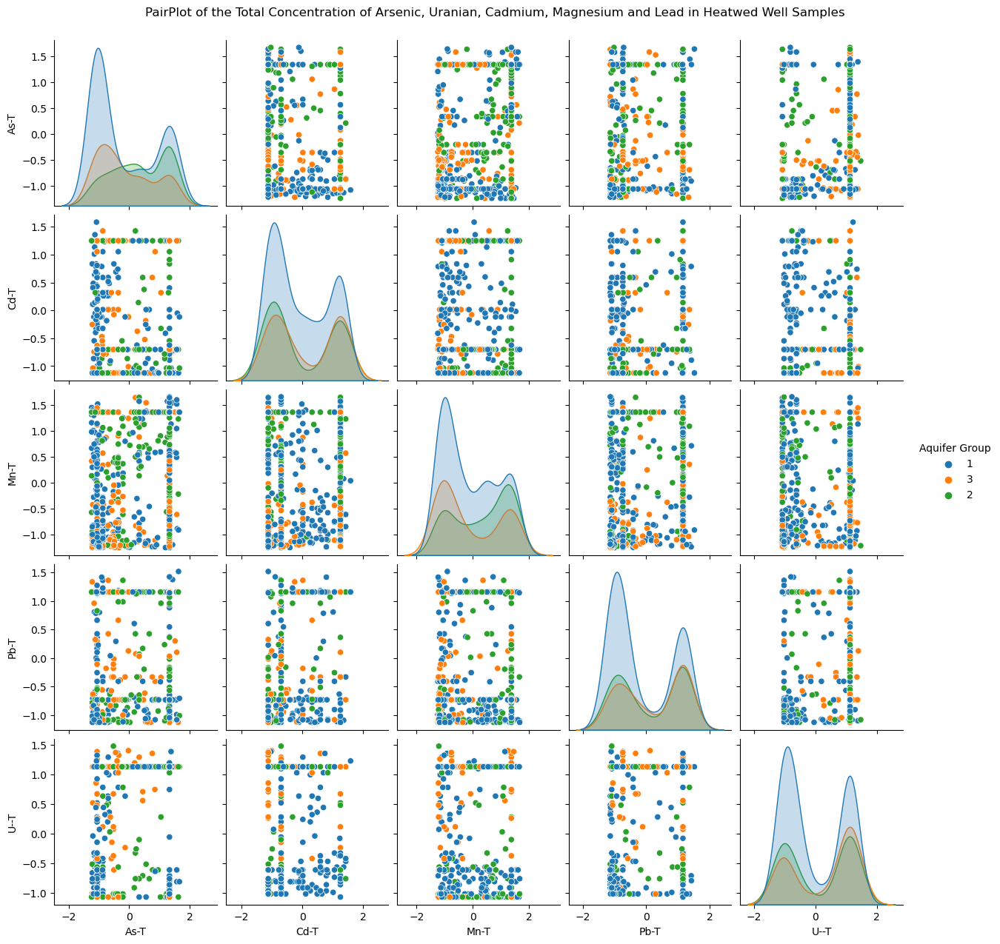

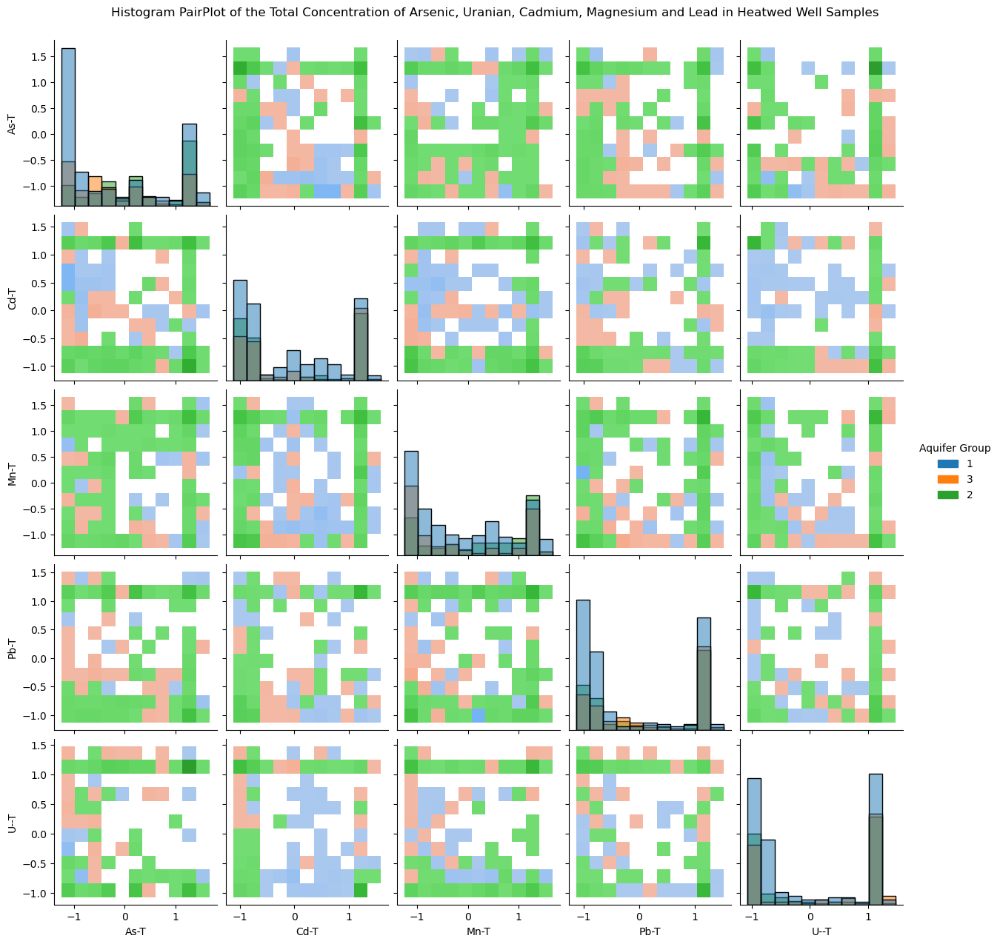

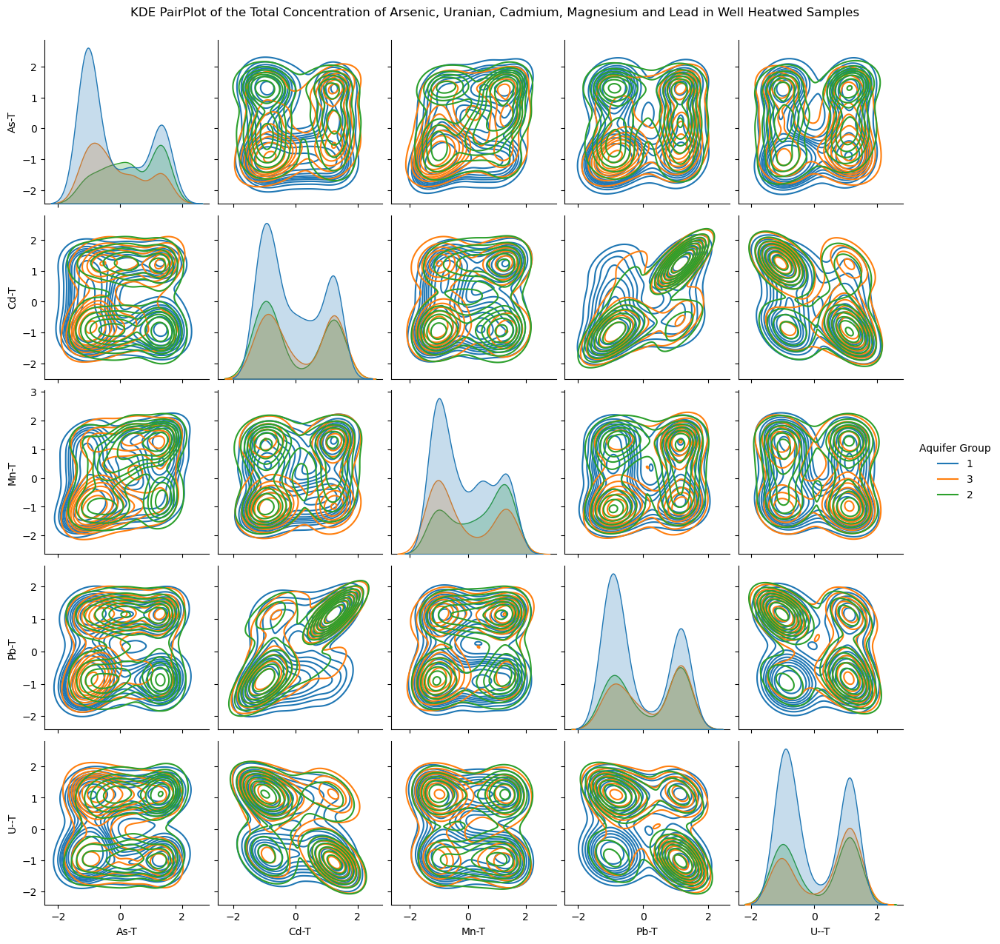

In [17]:
Metals_Total = df_Heatw[['As-T','Cd-T','Mn-T', 'Pb-T','U--T', 'Aquifer Group']]
Metalsg = sns.pairplot(Metals_Total, hue="Aquifer Group")
Metalsg.fig.suptitle("PairPlot of the Total Concentration of Arsenic, Uranian, Cadmium, Magnesium and Lead in Heatwed Well Samples", y=1.02)
plt.savefig('Figures/pairplotmetalsHeatw.png') # Save the first figure

Metalsh = sns.pairplot(Metals_Total, hue="Aquifer Group", kind="hist")
Metalsh.fig.suptitle("Histogram PairPlot of the Total Concentration of Arsenic, Uranian, Cadmium, Magnesium and Lead in Heatwed Well Samples", y=1.02)
plt.savefig('Figures/histplotmetalsHeatw.png') 

Metalsf = sns.pairplot(Metals_Total, hue="Aquifer Group", kind="kde")
Metalsf.fig.suptitle("KDE PairPlot of the Total Concentration of Arsenic, Uranian, Cadmium, Magnesium and Lead in Well Heatwed Samples", y=1.02)
plt.savefig('Figures/KDEplotmetalsHeatw.png') 


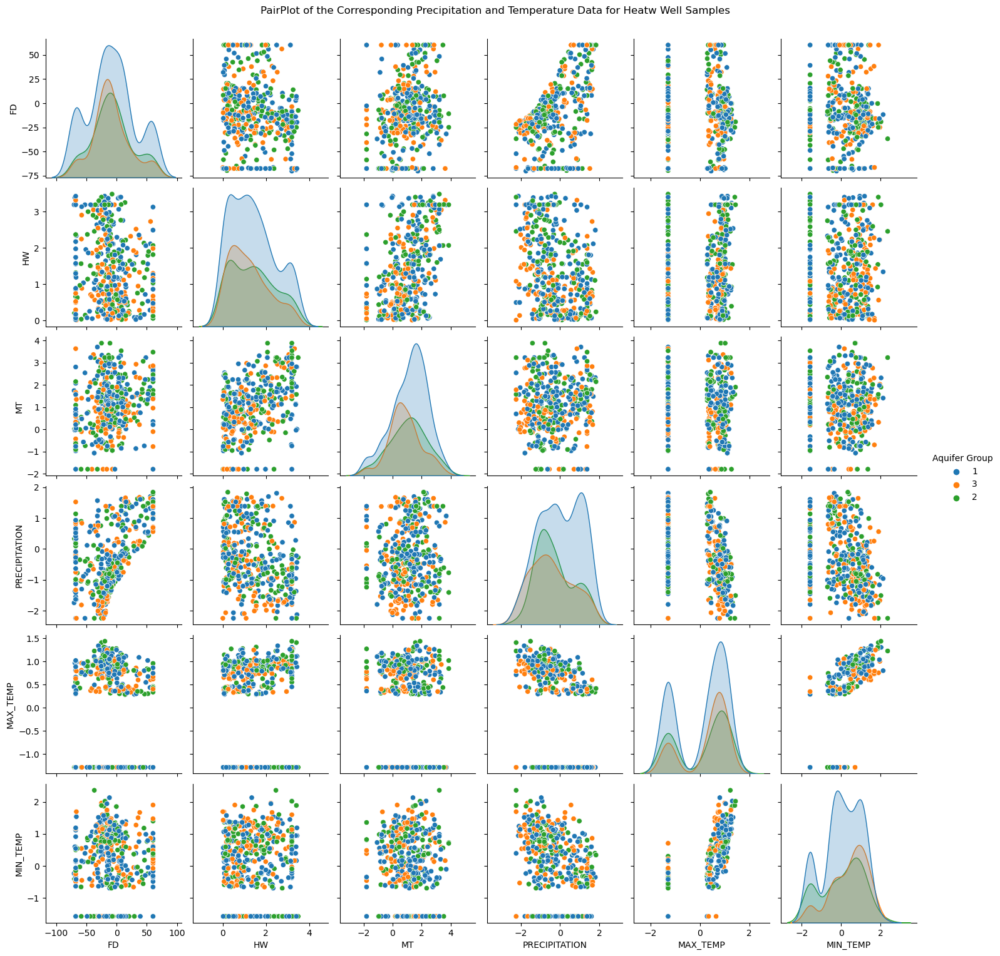

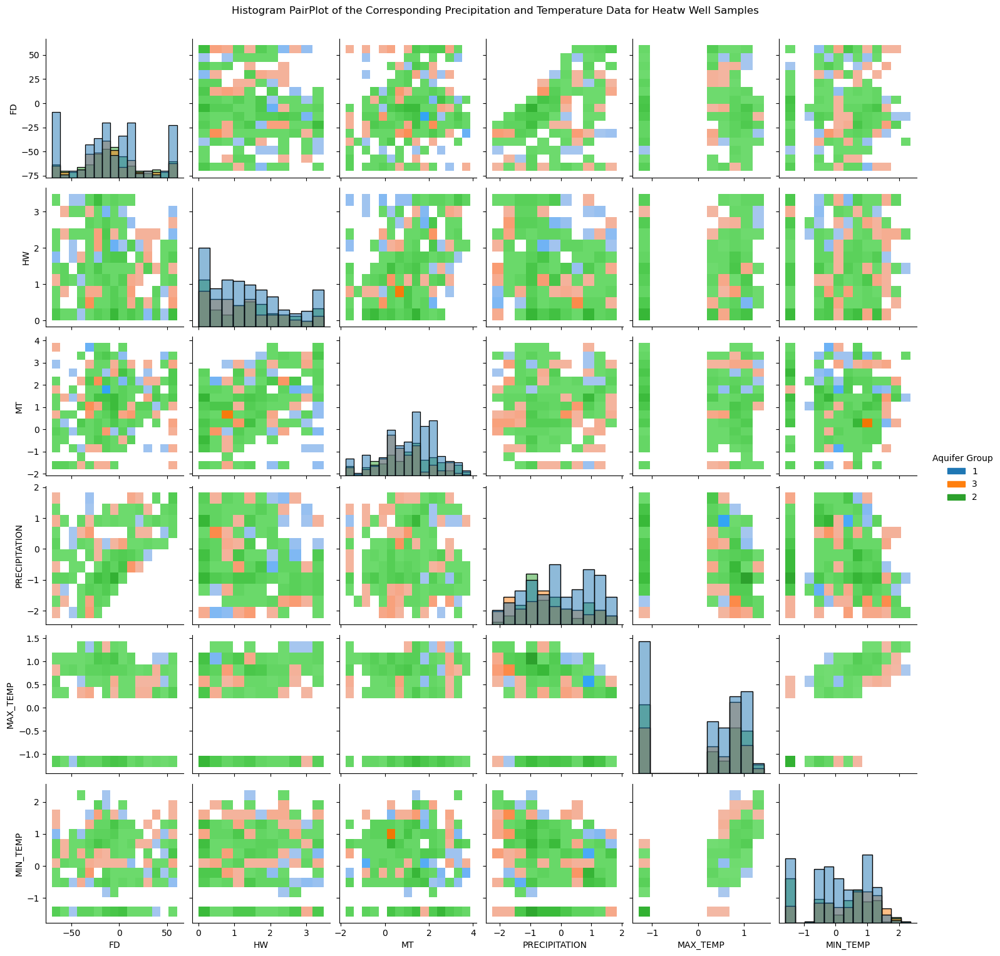

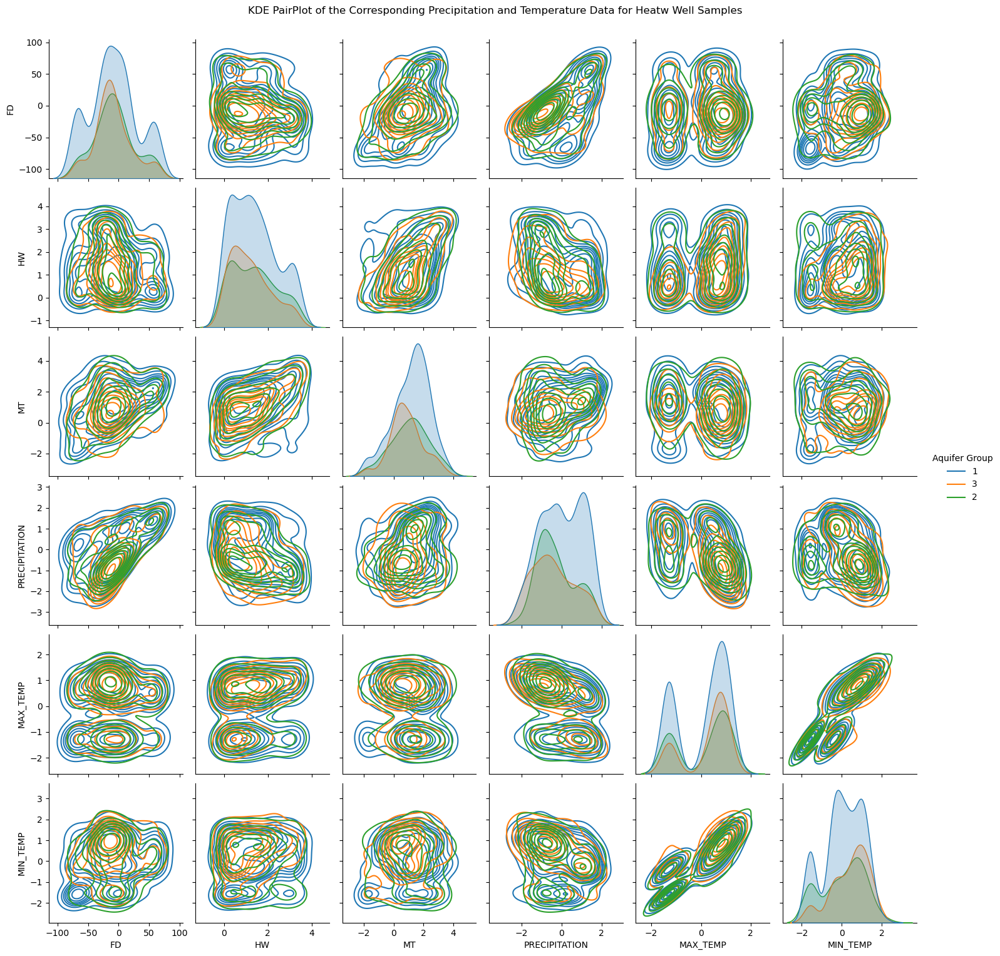

In [18]:
Precept = df_Heatw[['FD', 'HW', 'MT', 'Aquifer Group', 'PRECIPITATION', 'MAX_TEMP', 'MIN_TEMP']]
Preceptg= sns.pairplot(Precept, hue="Aquifer Group")
Preceptg.fig.suptitle("PairPlot of the Corresponding Precipitation and Temperature Data for Heatw Well Samples", y=1.02)
plt.savefig('Figures/pairplotPreceptHeatw.png') # Save the first figure

Precepth = sns.pairplot(Precept, hue="Aquifer Group", kind="hist")
Precepth.fig.suptitle("Histogram PairPlot of the Corresponding Precipitation and Temperature Data for Heatw Well Samples", y=1.02)
plt.savefig('Figures/histplotPreceptHeatw.png') 

Preceptf = sns.pairplot(Precept, hue="Aquifer Group", kind="kde")
Preceptf.fig.suptitle("KDE PairPlot of the Corresponding Precipitation and Temperature Data for Heatw Well Samples", y=1.02)
plt.savefig('Figures/KDEplotPreceptHeatw.png') 

In [19]:
OthersD = df_Heatw[['Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T', 'Chlrid:D', 'Fe-T',
       'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'pH', 'Hardness Total (T)', 'K--T',
       'U--T', 'Aquifer Group']]

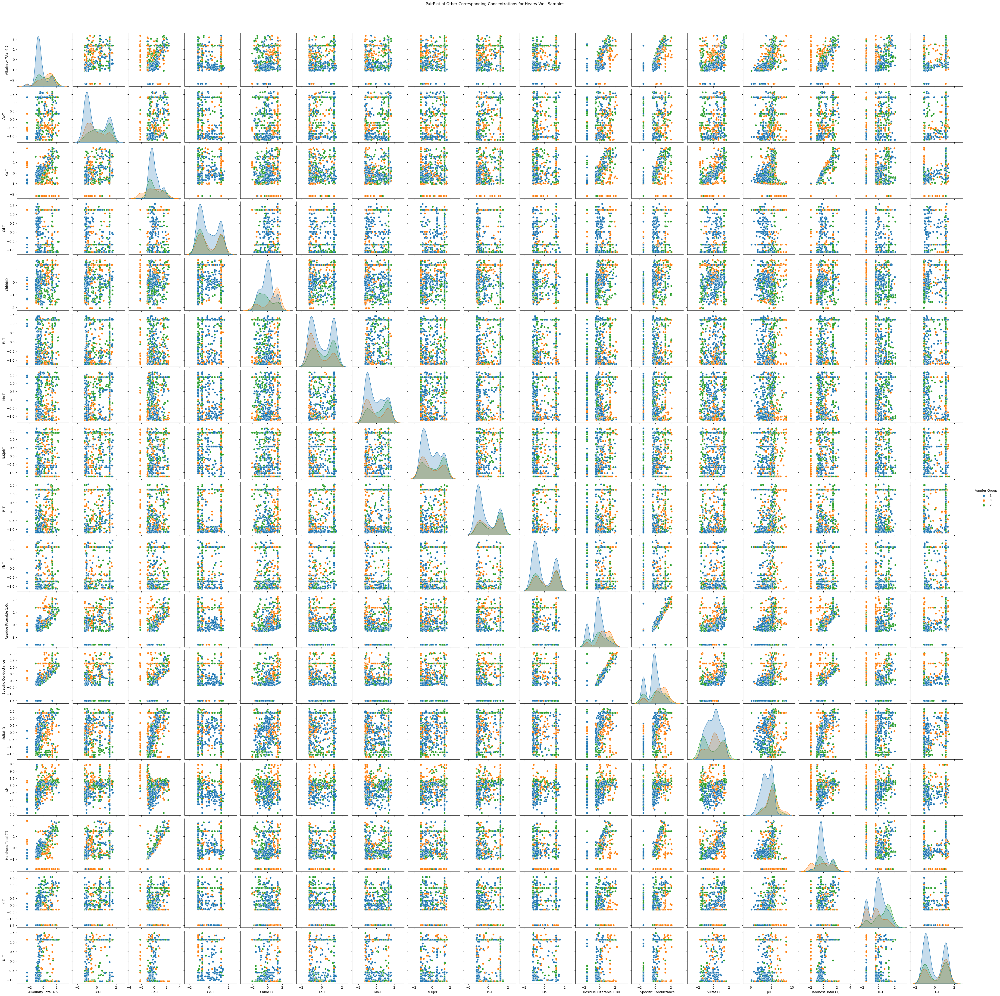

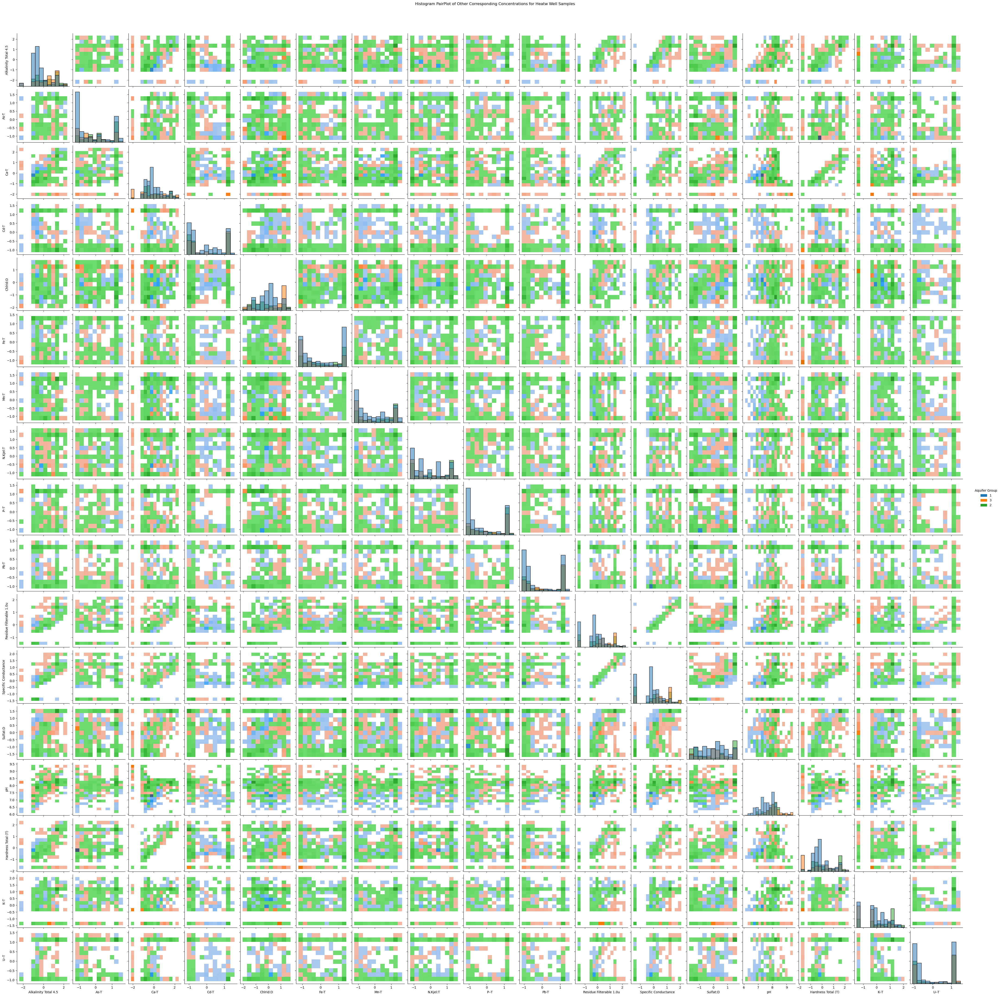

In [20]:
OthersDg= sns.pairplot(OthersD, hue="Aquifer Group")
OthersDg.fig.suptitle("PairPlot of Other Corresponding Concentrations for Heatw Well Samples", y=1.02)
plt.savefig('Figures/pairplotOthersDHeatw.png') # Save the first figure

OthersDh = sns.pairplot(OthersD, hue="Aquifer Group", kind="hist")
OthersDh.fig.suptitle("Histogram PairPlot of Other Corresponding Concentrations for Heatw Well Samples", y=1.02)
plt.savefig('Figures/histplotOthersDHeatw.png') 

In [21]:
df_Heatw.columns

Index(['Alkalinity Total 4.5', 'As-T', 'Ca-T', 'Cd-T', 'Chlrid:D', 'Fe-T',
       'Mn-T', 'N.Kjel:T', 'P--T', 'Pb-T', 'Residue Filterable 1.0u',
       'Specific Conductance', 'Sulfat:D', 'pH', 'Hardness Total (T)', 'K--T',
       'U--T', 'PRECIPITATION', 'MIN_TEMP', 'MAX_TEMP', 'FD', 'HW', 'MT',
       'Aquifer Group'],
      dtype='object')

In [22]:
df_Heatw.shape

(611, 24)

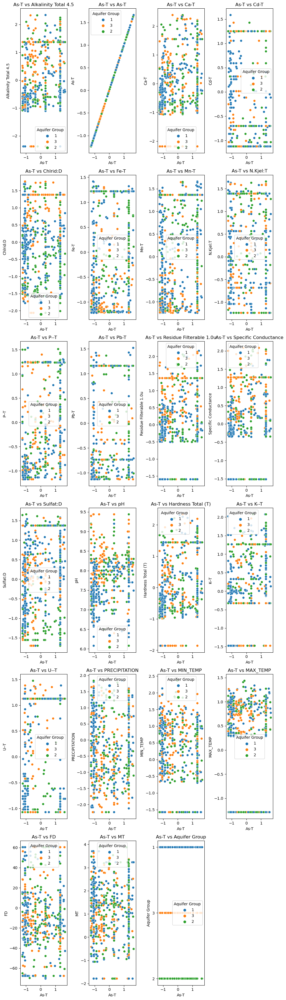

<Figure size 1000x800 with 0 Axes>

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming df_Heatw is your DataFrame and 'DF' is your column to exclude
pmetals = [col for col in df_Heatw.columns if col != 'HW']  # list of all metal columns

# Determine the layout of subplots
pn = len(pmetals)
pncols = 4  # number of columns of subplots
pnrows = pn // pncols if pn % pncols == 0 else pn // pncols + 1  # calculate number of rows needed

fig, axes = plt.subplots(nrows=pnrows, ncols=pncols, figsize=(10, 6 * pnrows))  # create a new figure with a subplot grid
axes = axes.flatten()  # flatten the axes array to loop through it easily

for i, pmetal in enumerate(pmetals):
    sns.scatterplot(x='As-T', y=pmetal, data=df_Heatw, hue='Aquifer Group', ax=axes[i])  # create a scatter plot
    axes[i].set_title(f'As-T vs {pmetal}')  # set title

# Remove any unused subplots
if len(pmetals) < len(axes):
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

plt.tight_layout()
plt.show()  # display the plot
plt.savefig('Figures/ASTHeatw.png') 

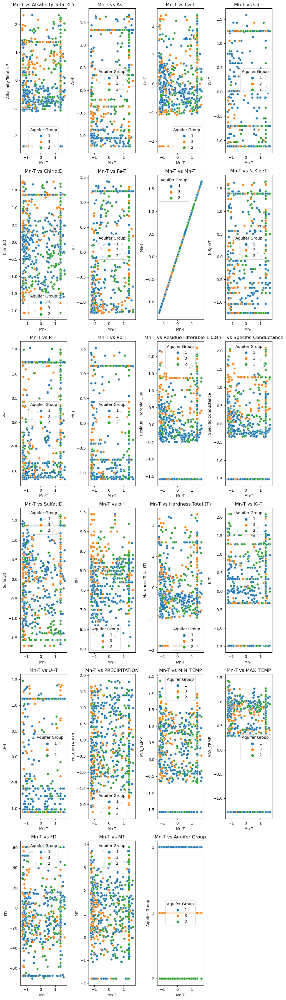

<Figure size 1000x800 with 0 Axes>

In [24]:
# Assuming df_Heatw is your DataFrame and 'DF' is your column to exclude
pmetals = [col for col in df_Heatw.columns if col != 'HW']  # list of all metal columns

# Determine the layout of subplots
pn = len(pmetals)
pncols = 4  # number of columns of subplots
pnrows = pn // pncols if pn % pncols == 0 else pn // pncols + 1  # calculate number of rows needed

fig, axes = plt.subplots(nrows=pnrows, ncols=pncols, figsize=(10, 6 * pnrows))  # create a new figure with a subplot grid
axes = axes.flatten()  # flatten the axes array to loop through it easily

for i, pmetal in enumerate(pmetals):
    sns.scatterplot(x='Mn-T', y=pmetal, data=df_Heatw, hue='Aquifer Group', ax=axes[i])  # create a scatter plot
    axes[i].set_title(f'Mn-T vs {pmetal}')  # set title

# Remove any unused subplots
if len(pmetals) < len(axes):
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

plt.tight_layout()
plt.show()  # display the plot
plt.savefig('Figures/MnTHeatw.png') 

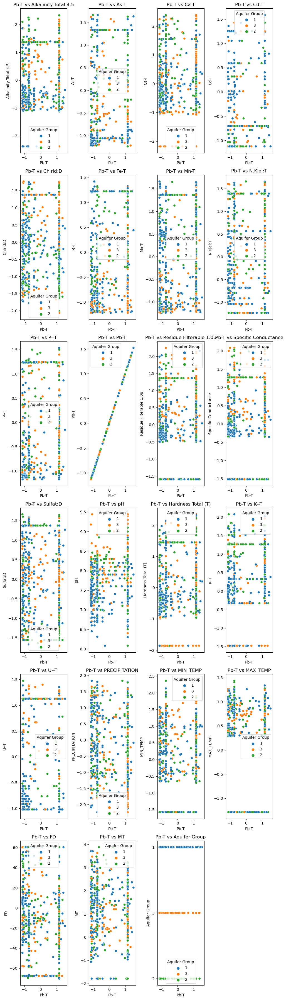

<Figure size 1000x800 with 0 Axes>

In [25]:
# Assuming df_Heatw is your DataFrame and 'DF' is your column to exclude
pmetals = [col for col in df_Heatw.columns if col != 'HW']  # list of all metal columns

# Determine the layout of subplots
pn = len(pmetals)
pncols = 4  # number of columns of subplots
pnrows = pn // pncols if pn % pncols == 0 else pn // pncols + 1  # calculate number of rows needed

fig, axes = plt.subplots(nrows=pnrows, ncols=pncols, figsize=(10, 6 * pnrows))  # create a new figure with a subplot grid
axes = axes.flatten()  # flatten the axes array to loop through it easily

for i, pmetal in enumerate(pmetals):
    sns.scatterplot(x='Pb-T', y=pmetal, data=df_Heatw, hue='Aquifer Group', ax=axes[i])  # create a scatter plot
    axes[i].set_title(f'Pb-T vs {pmetal}')  # set title

# Remove any unused subplots
if len(pmetals) < len(axes):
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

plt.tight_layout()
plt.show()  # display the plot
plt.savefig('Figures/PbTHeatw.png') 

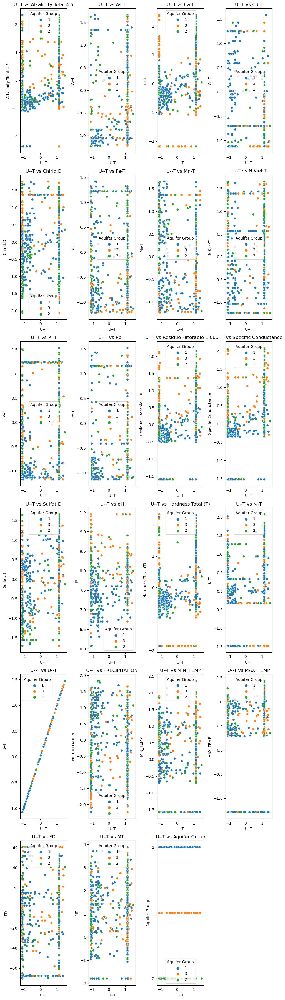

<Figure size 1000x800 with 0 Axes>

In [26]:
# Assuming df_Heatw is your DataFrame and 'DF' is your column to exclude
pmetals = [col for col in df_Heatw.columns if col != 'HW']  # list of all metal columns

# Determine the layout of subplots
pn = len(pmetals)
pncols = 4  # number of columns of subplots
pnrows = pn // pncols if pn % pncols == 0 else pn // pncols + 1  # calculate number of rows needed

fig, axes = plt.subplots(nrows=pnrows, ncols=pncols, figsize=(10, 6 * pnrows))  # create a new figure with a subplot grid
axes = axes.flatten()  # flatten the axes array to loop through it easily

for i, pmetal in enumerate(pmetals):
    sns.scatterplot(x='U--T', y=pmetal, data=df_Heatw, hue='Aquifer Group', ax=axes[i])  # create a scatter plot
    axes[i].set_title(f'U--T vs {pmetal}')  # set title

# Remove any unused subplots
if len(pmetals) < len(axes):
    for j in range(i+1, len(axes)):
        fig.delaxes(axes[j])

plt.tight_layout()
plt.show()  # display the plot
plt.savefig('Figures/UTHeatw.png') 